# Data Fitting

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/07-xray_reflectivity/03-data_fitting.ipynb)

In this example the simulations of the **udkm1Dsim** toolbox are fitted to experimental data by the external fitting package [lmfit](https://lmfit.github.io/lmfit-py/).
As in a typical experiment, the static structure of the sample, i.e. the thicknesses, roughnesses, and densities of its layers, is determined first by fitting its hard X-ray reflectivity.
Afterwards, the fitted structure is used to analyze the magnetization dynamics after an optical excitation by time-resolved resonant magnetic reflectivity in the soft X-ray range, which is sensitive to the depth profile of the magnetization.

Here, the W/Fe/W trilayer of {cite:t}`elzo2012` is used:

1. The measured hard X-ray reflectivity of Fig. 6 of the paper is fitted by the fast {py:class}`Parratt <udkm1Dsim.simulations.scattering.parratt.Parratt>` formalism.
2. The magnetization dynamics of the fitted structure are calculated by the microscopic three-temperature model (M3TM) of {cite:t}`koopmans2010`, see the [M3TM example](#example_m3tm), from which *experimental* resonant magnetic reflectivity data at the Fe $L_3$ edge are generated by the {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>` formalism, see the [example of resonant magnetic X-ray reflectivity](#example_resonant_magnetic_xray).
3. These data are fitted by analytical magnetization profiles for every delay, i.e. the inverse problem is solved.
4. Finally, the parameters of the M3TM are fitted to all delays at once by a forward simulation of the magnetization map.

:::{admonition} Reference {cite}`elzo2012`
:class: seealso
M. Elzo, et al., *X-ray resonant magnetic reflectivity of stratified magnetic structures: Eigenwave formalism and application to a W/Fe/W trilayer*, [J. Magn. Magn. Mater. 324, 105 (2012)](http://www.doi.org/10.1016/j.jmmm.2011.07.019)
:::

:::{note}
Only the hard X-ray reflectivity is measured data, while the resonant magnetic reflectivity is **generated** from a simulation with **estimated** parameters of the M3TM.
:::

## Setup

Do all necessary imports and settings.

In [1]:
from time import time

import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

try:
    import lmfit  # not a dependency of udkm1Dsim
except ImportError:
    %pip install lmfit
    import lmfit

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure from Hard X-ray Reflectivity

### Experimental Data

The reflectivity was measured by {cite:t}`elzo2012` with a laboratory Cu $K_\alpha$ source at the photon energy of 8051 eV, as stated in the paper.
It was digitized from Fig. 6 of the paper and is provided with the example.

In [2]:
theta_exp, R_exp = np.loadtxt("Elzo2012_Fig6_WFeW_8051eV.dat").T
theta_exp = theta_exp * u.deg

### Structure

Refer to the [structure example](#example_structure) for more details.

The measured data of {cite:t}`elzo2012` are fitted starting from a **made-up** nominal structure of W(3 nm)/Fe(10 nm)/W(15 nm) on a sapphire substrate with roughnesses of 0.5 nm and the bulk densities of the materials.
The roughness of a layer is the one of its top interface.
The dielectric tensors of the layers are calculated from the tabulated atomic form factors of their atoms, where the form factors of Fe also include its $L$ edges for the resonant magnetic reflectivity below, see the [example of the dielectric tensor](#example_dielectric).

In [3]:
W = ud.Atom("W")
# measured form factors of Fe also around its L edges
Fe = ud.Atom("Fe", atomic_form_factor_path="./Fe.cf")
Al2O3 = ud.AtomMixed("Al2O3", name="Al2O3")
Al2O3.add_atom(ud.Atom("Al"), 2 / 5)
Al2O3.add_atom(ud.Atom("O"), 3 / 5)

start = {
    # made-up thickness (nm), bulk density (kg/m³), and roughness (nm)
    "W_top": (W, 3, 19300, 0.5),
    "Fe": (Fe, 10, 7874, 0.5),
    "W_bottom": (W, 15, 19300, 0.5),
    "Al2O3": (Al2O3, 0, 3987, 0.5),
}
layers = {}
for name, (atom, thickness, density, roughness) in start.items():
    layers[name] = ud.AmorphousLayer(
        name,
        name,
        atom=atom,
        structural=ud.StructuralParameters(
            thickness=thickness * u.nm,
            density=density * u.kg / u.m**3,
            roughness=roughness * u.nm,
        ),
    )
    layers[name].set_dielectric_from_atoms()

S = ud.Structure("W/Fe/W")
for name in ["W_top", "Fe", "W_bottom"]:
    S.add_sub_structure(layers[name], 1)
S.add_substrate(layers["Al2O3"])
S

times,sub-structure,thickness
1,W_top,3 nm
1,Fe,10 nm
1,W_bottom,15 nm


### Reflectivity of the Starting Structure

The `Parratt` simulation is set to the energy and angles of the experiment and the $\sigma$ polarization, which is close to the $\pi$ polarization at these small angles, see the [scattering overview](#example_scattering_overview) for the experiment parameters and polarizations.

In [4]:
parratt = ud.Parratt(S, True, save_data=False, disp_messages=False)
parratt.energy = np.r_[8051] * u.eV
parratt.theta = theta_exp
parratt.set_polarization("sigma", "none")

res_start = parratt.homogeneous_reflectivity_transmissivity()
R_start = res_start.R[0, :]

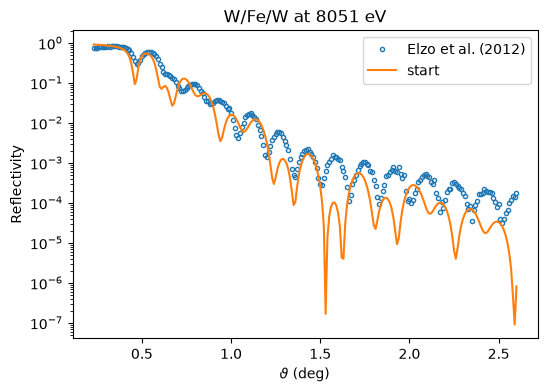

In [5]:
plt.figure(figsize=[6, 4])
plt.semilogy(theta_exp, R_exp, "o", ms=3, mfc="none", label="Elzo et al. (2012)")
plt.semilogy(res_start.quantity("theta", "deg")[0], R_start, label="start")
plt.xlabel(r"$\vartheta$ (deg)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("W/Fe/W at 8051 eV")
plt.show()

The starting structure already shows the Kiessig fringes of the total thickness and their beating by the thinner layers, but their period and damping deviate from the measurement.
Below the critical angle of total reflection of W at about 0.5°, the measured reflectivity drops, as the beam footprint exceeds the sample at grazing incidence, which is not included here.

### Sensitivity to the Structure

The period of the fringes is given by the thickness of the layers, while the roughness damps the reflectivity and the fringes towards larger angles.

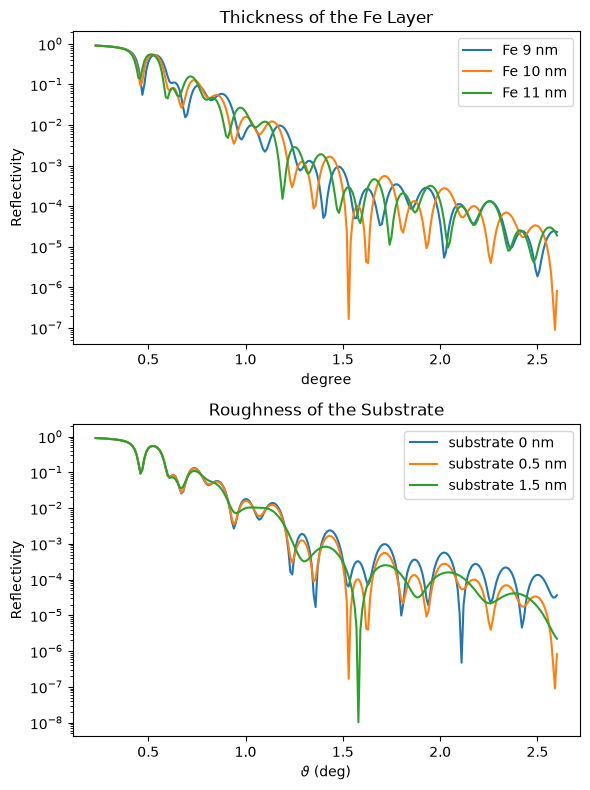

In [6]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
for thickness in [9, 10, 11]:
    layers["Fe"].structural.thickness = thickness * u.nm
    R = parratt.homogeneous_reflectivity_transmissivity().R[0, :]
    plt.semilogy(theta_exp, R, label=f"Fe {thickness} nm")
layers["Fe"].structural.thickness = 10 * u.nm
plt.ylabel("Reflectivity")
plt.legend()
plt.title("Thickness of the Fe Layer")

plt.subplot(2, 1, 2)
for roughness in [0, 0.5, 1.5]:
    layers["Al2O3"].structural.roughness = roughness * u.nm
    R = parratt.homogeneous_reflectivity_transmissivity().R[0, :]
    plt.semilogy(theta_exp, R, label=f"substrate {roughness} nm")
layers["Al2O3"].structural.roughness = 0.5 * u.nm
plt.xlabel(r"$\vartheta$ (deg)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("Roughness of the Substrate")

plt.tight_layout()
plt.show()

### Comparison of the Multilayer Formalisms

All multilayer formalisms calculate the same non-magnetic X-ray reflectivity, see the [scattering overview](#example_scattering_overview).
Here, they are compared for the starting structure with their computation times, which are taken for the plain arrays of {py:meth}`calc_homogeneous_reflectivity_transmissivity <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.calc_homogeneous_reflectivity_transmissivity>`, see the hint below.

In [7]:
formalisms = [ud.Parratt, ud.Elzo, ud.Stepanov, ud.BerremanElzo, ud.BerremanStepanov]

R_formalisms = {}
computation_time = {}
for formalism in formalisms:
    sim = formalism(S, True, save_data=False, disp_messages=False)
    sim.energy = np.r_[8051] * u.eV
    sim.theta = theta_exp
    sim.set_polarization("sigma", "none")
    t0 = time()
    R, _, _, _ = sim.calc_homogeneous_reflectivity_transmissivity()
    R_formalisms[formalism.__name__] = R[0, :]
    computation_time[formalism.__name__] = (time() - t0) * 1e3  # ms

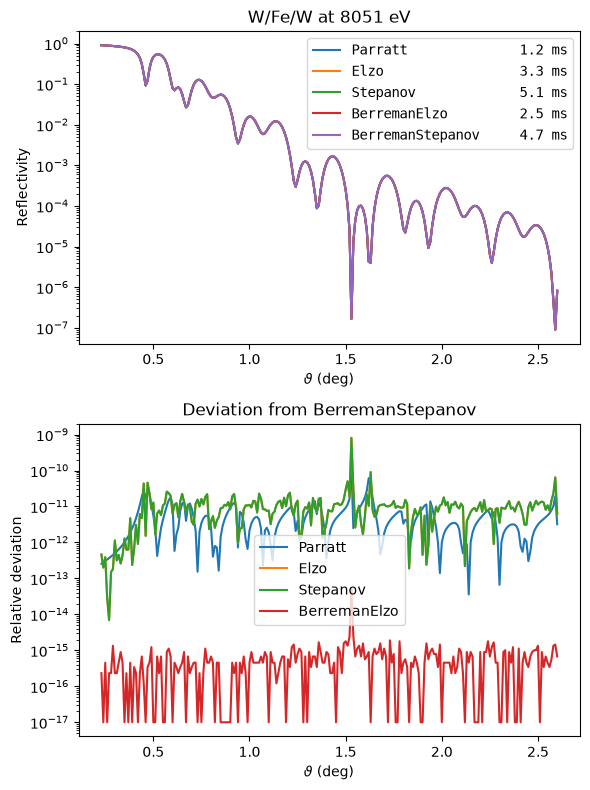

In [8]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
for name, R in R_formalisms.items():
    plt.semilogy(theta_exp, R, label=f"{name:17s} {computation_time[name]:6.1f} ms")
plt.xlabel(r"$\vartheta$ (deg)")
plt.ylabel("Reflectivity")
plt.legend(prop={"family": "monospace"})
plt.title("W/Fe/W at 8051 eV")

plt.subplot(2, 1, 2)
for name, R in R_formalisms.items():
    if name != "BerremanStepanov":
        plt.semilogy(
            theta_exp, np.abs(R / R_formalisms["BerremanStepanov"] - 1) + 1e-17, label=name
        )
plt.xlabel(r"$\vartheta$ (deg)")
plt.ylabel("Relative deviation")
plt.legend()
plt.title("Deviation from BerremanStepanov")

plt.tight_layout()
plt.show()

All formalisms agree with the exact `BerremanStepanov` far below any experimental accuracy.
`Parratt` and `BerremanElzo` agree within the numerical precision, while `Elzo` and `Stepanov` deviate by up to $10^{-10}$ due to the limited numerical precision of their eigenmodes.
As the Fe layer is not magnetized here, all formalisms give the same reflectivity, while `Parratt` is the fastest one, as it only recurses the scalar reflection coefficients of $\sigma$ and $\pi$ instead of assembling $4 \times 4$ matrices.
Hence, the structure is fitted by `Parratt`, but any other formalism gives the same result, only slower, and is required for magnetic or anisotropic layers, e.g. close to an absorption edge, see the [example of resonant magnetic X-ray reflectivity](#example_resonant_magnetic_xray).

### Fit of the Structure

The thicknesses and roughnesses of the layers are fitted to the logarithm of the measured reflectivity by [lmfit](https://lmfit.github.io/lmfit-py/), together with a scale factor of the digitized intensity.
The angles below 0.5° are excluded due to the footprint.
As the thicknesses of the layers are correlated, the fit has several local minima.
Hence, the global minimum is searched first by the `differential_evolution` of lmfit within the bounds of the parameters, which requires several thousand calculations, before a local least-squares fit gives the uncertainties.
A single `Parratt` calculation takes only milliseconds, so that the whole fit takes a few seconds.

:::{hint}
All fits call the `calc_*()` methods of the simulations, e.g. {py:meth}`calc_homogeneous_reflectivity_transmissivity <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.calc_homogeneous_reflectivity_transmissivity>`, instead of the `homogeneous_*()`, `inhomogeneous_*()`, and `get_*()` methods.
They return plain numpy arrays without the cache and the metadata of a {py:class}`Result <udkm1Dsim.simulations.result.Result>`, see the [simulations and results example](#example_simulations_and_results).
A fit calculates every set of parameters only once, so that it gains nothing from the cache, while the metadata, e.g. the structure as YAML and the parameters of the simulation, take about 20 ms for every call, which is much longer than a single `Parratt` calculation.
:::

In [9]:
fitted = ["W_top", "Fe", "W_bottom"]


def reflectivity(params):
    for name in fitted:
        layers[name].structural.thickness = params[f"d_{name}"] * u.nm
        layers[name].structural.roughness = params[f"sigma_{name}"] * u.nm
    layers["Al2O3"].structural.roughness = params["sigma_Al2O3"] * u.nm
    R, _, _, _ = parratt.calc_homogeneous_reflectivity_transmissivity()
    return params["scale"] * R[0, :]


params = lmfit.Parameters()
for name in fitted:
    _, thickness, _, roughness = start[name]
    params.add(f"d_{name}", thickness, min=0.8 * thickness, max=1.2 * thickness)
    params.add(f"sigma_{name}", roughness, min=0, max=2)
params.add("sigma_Al2O3", start["Al2O3"][3], min=0, max=2)
params.add("scale", 1, min=0.5, max=2)

mask = theta_exp >= 0.5 * u.deg


def residual(params):
    return np.log10(reflectivity(params)[mask]) - np.log10(R_exp[mask])


global_result = lmfit.minimize(residual, params, method="differential_evolution", seed=0)
result = lmfit.minimize(residual, global_result.params)
R_fit = reflectivity(result.params)
result

In [10]:
table_1 = {  # thickness and roughness (nm) of Table 1 of Elzo et al. (2012)
    "W_top": (3.13, 0.14),
    "Fe": (9.15, 0.51),
    "W_bottom": (13.41, 1.16),
    "Al2O3": (0, 0.59),
}
print(f"{'':12s} {'Table 1':>8s} {'fit':>14s}")
for name in fitted:
    thickness, roughness = table_1[name]
    d, sigma = result.params[f"d_{name}"], result.params[f"sigma_{name}"]
    print(f"d {name:10s} {thickness:8.2f} {d.value:8.2f} ± {d.stderr:.2f} nm")
    print(f"σ {name:10s} {roughness:8.2f} {sigma.value:8.2f} ± {sigma.stderr:.2f} nm")
sigma = result.params["sigma_Al2O3"]
print(f"σ {'Al2O3':10s} {table_1['Al2O3'][1]:8.2f} {sigma.value:8.2f} ± {sigma.stderr:.2f} nm")

              Table 1            fit
d W_top          3.13     3.01 ± 0.03 nm
σ W_top          0.14     0.27 ± 0.01 nm
d Fe             9.15     8.53 ± 0.15 nm
σ Fe             0.51     0.70 ± 0.02 nm
d W_bottom      13.41    13.42 ± 0.15 nm
σ W_bottom       1.16     1.64 ± 0.16 nm
σ Al2O3          0.59     0.43 ± 0.01 nm


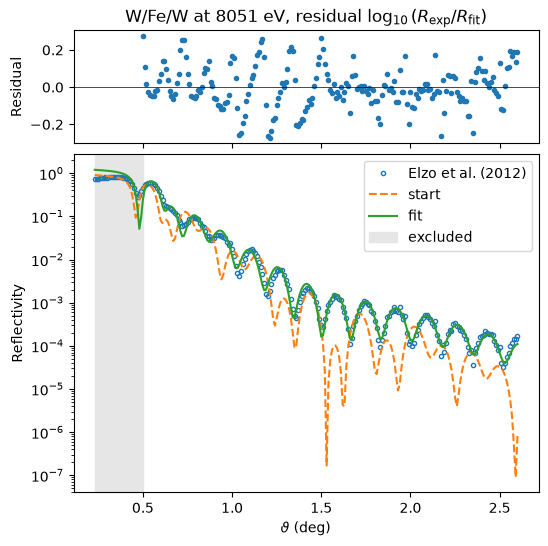

In [11]:
fig, (ax_res, ax_R) = plt.subplots(
    2, 1, figsize=[6, 6], sharex=True, gridspec_kw={"height_ratios": [1, 3], "hspace": 0.05}
)
ax_res.plot(theta_exp[mask], np.log10(R_exp[mask] / R_fit[mask]), ".")
ax_res.axhline(0, color="k", lw=0.5)
ax_res.set_ylabel("Residual")
ax_res.set_title(r"W/Fe/W at 8051 eV, residual $\log_{10}(R_\mathrm{exp} / R_\mathrm{fit})$")

ax_R.semilogy(theta_exp, R_exp, "o", ms=3, mfc="none", label="Elzo et al. (2012)")
ax_R.semilogy(theta_exp, R_start, "--", label="start")
ax_R.semilogy(theta_exp, R_fit, label="fit")
ax_R.axvspan(theta_exp[0].m_as("deg"), 0.5, color="0.9", label="excluded")
ax_R.set_xlabel(r"$\vartheta$ (deg)")
ax_R.set_ylabel("Reflectivity")
ax_R.legend()
plt.show()

The fit corrects the period and the damping of the fringes, together with the scale factor of the digitized intensity.
The fitted thicknesses and roughnesses are close to the ones of Table 1 of {cite:t}`elzo2012`, which they obtained from their refinement of these data.

:::{note}
The footprint correction and the angular resolution of the instrument are planned for a future version, which will also allow fitting the angles below 0.5°.
:::

## Magnetization Dynamics from Resonant Magnetic Reflectivity

The fitted structure is now used to analyze the demagnetization of the Fe layer after an optical excitation by the resonant magnetic reflectivity of circularly polarized soft X-rays at the Fe $L_3$ edge at 706.8 eV, as measured by {cite:t}`elzo2012`.
As in the longitudinal geometry (LXRMR) of {cite:t}`elzo2012`, the magnetization lies in the surface and in the plane of incidence along $y$ and the X-rays are circularly polarized, so that the asymmetry of the reflectivity is sensitive to the depth profile of the magnetization.

### Structure with Depth Resolution

For a depth-resolved magnetization, the Fe layer is divided into 9 sub-layers, where only the top one has the fitted roughness of the Fe layer.
The thicknesses and roughnesses of all layers are taken from the fit above.

The parameters of the M3TM are **estimated**: the electronic heat capacities $\gamma_e T_e$, the electron-phonon couplings $g$, the electronic thermal conductivities $\kappa_e T_e / T_p$, and the demagnetization rate $R$ and Curie temperature $T_C$ of Fe, where the magnetization is the 3rd sub-system, see the [M3TM example](#example_m3tm).
Only the electronic thermal conductivity of Fe is **made up** with $\kappa_e$ = 2 W/(m K) instead of about 80 W/(m K), which results in a pronounced inhomogeneous magnetization profile.
The refractive indices at the pump wavelength of 800 nm are used as fallback of the atomic form factors, see the [example of resonant magnetic X-ray reflectivity](#example_resonant_magnetic_xray).

In [12]:
N_Fe = 9  # number of sub-layers of Fe
d = {name: result.params[f"d_{name}"].value for name in fitted}  # fitted thicknesses (nm)
sigma = {name: result.params[f"sigma_{name}"].value for name in fitted + ["Al2O3"]}  # (nm)

# estimated M3TM parameters of Fe
rho_Fe = 7875  # density (kg/m³)
gamma_Fe = 670 / rho_Fe  # electronic heat capacity (J/kg/K²)
g_Fe = 7e17  # electron-phonon coupling (W/m³/K)
R_Fe = 20e12  # demagnetization rate (1/s)
Tc = 1044  # Curie temperature (K)

thermal_W = ud.ThermalParameters(
    heat_capacity=[f"{137 / 19300}*T", 132 * u.J / u.kg / u.K, 1],
    therm_cond=["170*T_0/T_1", 3 * u.W / (u.m * u.K), 0],
    sub_system_coupling=["-2e17*(T_0-T_1)", "2e17*(T_0-T_1)", 0],
    sub_system_labels=["e", "p", "m"],
)
thermal_Fe = ud.ThermalParameters(
    heat_capacity=[f"{gamma_Fe}*T", 450 * u.J / u.kg / u.K, 1 / rho_Fe],
    therm_cond=["2*T_0/T_1", 3 * u.W / (u.m * u.K), 0],  # made-up low kappa_e
    sub_system_coupling=[
        f"-{g_Fe}*(T_0-T_1)",
        f"{g_Fe}*(T_0-T_1)",
        f"{R_Fe}*T_2*T_1/{Tc}*(1-T_2*(1+2/(exp(2*T_2*{Tc}/T_0)-1)))",
    ],
    sub_system_labels=["e", "p", "m"],
)
thermal_Al2O3 = ud.ThermalParameters(
    heat_capacity=[1, 775 * u.J / u.kg / u.K, 1],
    therm_cond=[0, 30 * u.W / (u.m * u.K), 0],
    sub_system_coupling=[0, 0, 0],
    sub_system_labels=["e", "p", "m"],
)

In [13]:
W_top = ud.AmorphousLayer(
    "W_top",
    "W top",
    atom=W,
    structural=ud.StructuralParameters(
        thickness=d["W_top"] * u.nm, density=19300 * u.kg / u.m**3, roughness=sigma["W_top"] * u.nm
    ),
    thermal=thermal_W,
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(3.68 + 2.89j)),
)
Fe_top = ud.AmorphousLayer(
    "Fe_top",
    "Fe top",
    atom=Fe,
    structural=ud.StructuralParameters(
        thickness=d["Fe"] / N_Fe * u.nm,
        density=rho_Fe * u.kg / u.m**3,
        roughness=sigma["Fe"] * u.nm,
    ),
    thermal=thermal_Fe,
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.87 + 3.36j)),
    magnetic=ud.MagneticParameters(magnetization=(0, 1, 0)),  # longitudinal along y
)
Fe_bulk = ud.AmorphousLayer(
    "Fe",
    "Fe",
    atom=Fe,
    structural=ud.StructuralParameters(
        thickness=d["Fe"] / N_Fe * u.nm, density=rho_Fe * u.kg / u.m**3
    ),
    thermal=thermal_Fe,
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.87 + 3.36j)),
    magnetic=ud.MagneticParameters(magnetization=(0, 1, 0)),
)
W_bottom = ud.AmorphousLayer(
    "W_bottom",
    "W bottom",
    atom=W,
    structural=ud.StructuralParameters(
        thickness=d["W_bottom"] * u.nm,
        density=19300 * u.kg / u.m**3,
        roughness=sigma["W_bottom"] * u.nm,
    ),
    thermal=thermal_W,
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(3.68 + 2.89j)),
)
substrate = ud.AmorphousLayer(
    "Al2O3",
    "Al2O3",
    atom=Al2O3,
    structural=ud.StructuralParameters(
        thickness=0 * u.nm, density=3876 * u.kg / u.m**3, roughness=sigma["Al2O3"] * u.nm
    ),
    thermal=thermal_Al2O3,
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(1.76)),
)
# the refractive indices at 800 nm are kept as fallback of the form factors
for layer in [W_top, Fe_top, Fe_bulk, W_bottom, substrate]:
    layer.set_dielectric_from_atoms(fallback=layer.dielectric.eps0)

S_mag = ud.Structure("W/Fe/W with Fe sub-layers")
S_mag.add_sub_structure(W_top, 1)
S_mag.add_sub_structure(Fe_top, 1)
S_mag.add_sub_structure(Fe_bulk, N_Fe - 1)
S_mag.add_sub_structure(W_bottom, 1)
S_mag.add_substrate(substrate)
S_mag

times,sub-structure,thickness
1,W top,3.006 nm
1,Fe top,0.9479 nm
8,Fe,7.584 nm
1,W bottom,13.42 nm


### M3TM

Refer to the [M3TM example](#example_m3tm) for more details.

The absorbed energy of the pump pulse of 50 fs at 800 nm is calculated for the whole multilayer, so that the W capping layer is included.
The fluence of 2 mJ/cm² is **estimated**, such that the Fe layer is demagnetized by about 30 %.
The initial magnetization is the equilibrium $m = \tanh(m T_C / T)$ of the M3TM at 300 K, while the non-magnetic layers have no magnetization.

The amplitude of the M3TM becomes the $y$-component of the `magnetization_map`, which is put into a {py:class}`Result <udkm1Dsim.simulations.result.Result>` with the coordinates of the heat simulation, so that its `delays` are passed on to the resonant magnetic reflectivity, see the [simulations and results example](#example_simulations_and_results).
Alternatively, the `magnetization_map` can be given as plain numpy array, as in the [transient Kerr effect example](#example_transient_kerr_effect).

In [14]:
delays = np.r_[-0.5:3:0.05] * u.ps
L = S_mag.num_layers
Fe_layers = np.r_[1 : N_Fe + 1]  # indices of the Fe sub-layers
depth_Fe = (np.r_[0:N_Fe] + 0.5) * d["Fe"] / N_Fe  # center of the Fe sub-layers (nm)

m_eq = 1
for _ in range(100):
    m_eq = np.tanh(m_eq * Tc / 300)
init_temp = np.zeros([L, 3])
init_temp[:, :2] = 300
init_temp[Fe_layers, 2] = m_eq

h = ud.Heat(S_mag, True, save_data=False, disp_messages=False, progress_bar=False)
h.excitation = {
    "fluence": [2] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [0.05] * u.ps,
    "multilayer_absorption": True,
    "wavelength": 800 * u.nm,
    "theta": 45 * u.deg,
}
h.heat_diffusion = True
h.boundary_conditions = {"top_type": "isolator", "bottom_type": "isolator"}
res_temp = h.get_temp_map(delays, init_temp)

# the amplitude of the M3TM becomes the y-component of the magnetization map,
# which is put into a result with the coordinates of the heat simulation
magnetization_map = np.zeros([len(delays), L, 3])
magnetization_map[:, :, 1] = res_temp.temp_map[:, :, 2]
res_mag = ud.Result("magnetization map")
res_mag.copy_coords(res_temp)
res_mag.add("magnetization_map", magnetization_map, ("delays", "distances", "components"))

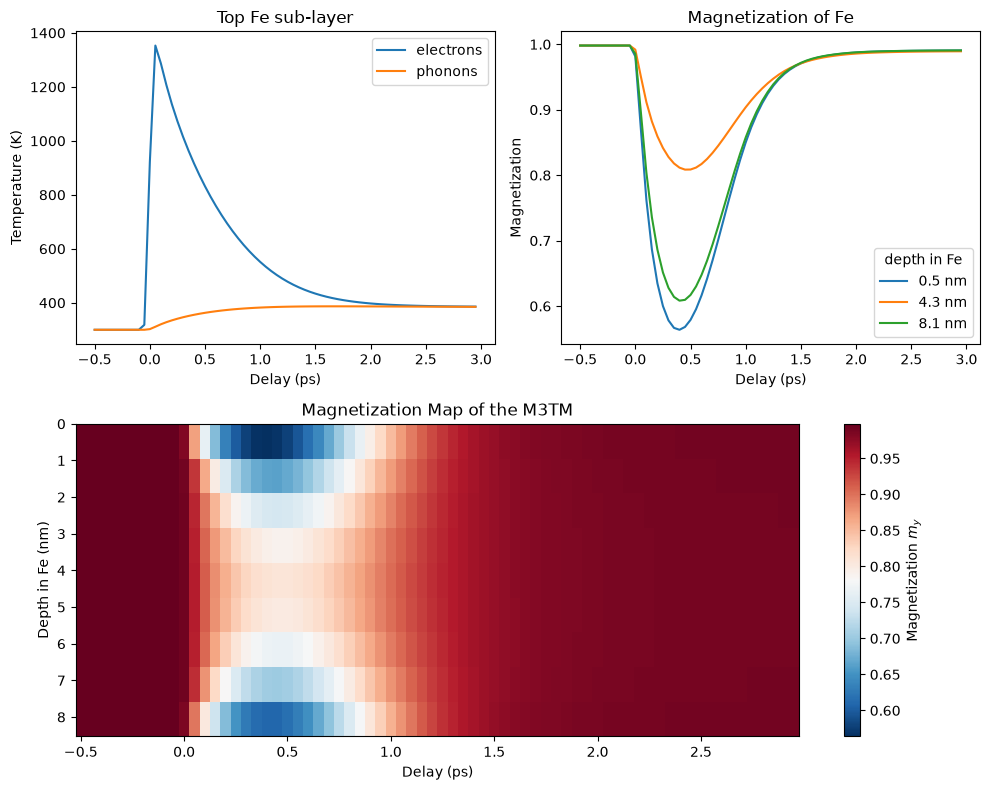

In [15]:
plt.figure(figsize=[10, 8])
plt.subplot(2, 2, 1)
delays_ps = res_temp.quantity("delays", "ps")
plt.plot(delays_ps, res_temp.temp_map[:, Fe_layers[0], 0], label="electrons")
plt.plot(delays_ps, res_temp.temp_map[:, Fe_layers[0], 1], label="phonons")
plt.xlabel("Delay (ps)")
plt.ylabel("Temperature (K)")
plt.legend()
plt.title("Top Fe sub-layer")

plt.subplot(2, 2, 2)
for j in [0, N_Fe // 2, N_Fe - 1]:
    plt.plot(delays_ps, res_temp.temp_map[:, Fe_layers[j], 2], label=f"{depth_Fe[j]:.1f} nm")
plt.xlabel("Delay (ps)")
plt.ylabel("Magnetization")
plt.legend(title="depth in Fe")
plt.title("Magnetization of Fe")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    delays_ps,
    depth_Fe,
    res_mag.magnetization_map[:, Fe_layers, 1].T,
    shading="nearest",
    cmap="RdBu_r",
)
plt.gca().invert_yaxis()
plt.colorbar(label="Magnetization $m_y$")
plt.xlabel("Delay (ps)")
plt.ylabel("Depth in Fe (nm)")
plt.title("Magnetization Map of the M3TM")
plt.tight_layout()
plt.show()

The hot electrons demagnetize the Fe layer within a few hundred femtoseconds, which recovers within about a picosecond after the electrons and phonons equilibrated.
Due to the low electronic thermal conductivity of Fe, the magnetization profile is strongly inhomogeneous: the hot electrons of both W layers heat the interfaces of the Fe layer, so that its top and bottom are demagnetized more strongly than its center.

### *Experimental* Data

The asymmetry $A = (R^+ - R^-) / (R^+ + R^-)$ of the reflectivity of circularly polarized X-rays for opposite magnetization, i.e. `R` and `R_phi`, which equals the one for opposite helicity of {cite:t}`elzo2012` in the longitudinal geometry, is calculated by {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>` for grazing angles up to 30° for all delays, see the [scattering overview](#example_scattering_overview) for the experiment parameters and polarizations.
Gaussian noise with a standard deviation of 0.01 is added to mimic *experimental* data.
The transient change $\Delta A$ of the asymmetry with respect to the one before the excitation follows the demagnetization at all angles.

In [16]:
elzo = ud.Elzo(S_mag, True, save_data=False, disp_messages=False, progress_bar=False)
elzo.energy = np.r_[706.8] * u.eV
elzo.theta = np.r_[1:30:0.1] * u.deg
elzo.set_polarization("circ +", "none")

res_exp = elzo.inhomogeneous_reflectivity_transmissivity(magnetization_map=res_mag)
R, R_phi = res_exp.R, res_exp.R_phi
rng = np.random.default_rng(0)
exp_asym = ((R - R_phi) / (R + R_phi))[:, 0, :]
exp_asym = exp_asym + rng.normal(0, 0.01, exp_asym.shape)
# coordinates of the result, the delays are passed on by the magnetization map
theta = res_exp.quantity("theta", "deg")[0, :]
delays_ps = res_exp.quantity("delays", "ps")

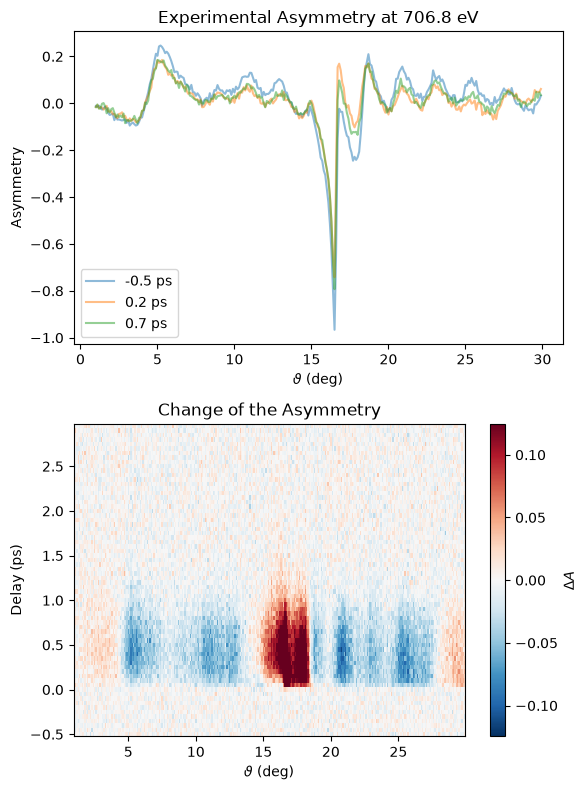

In [17]:
before = delays_ps < 0
exp_change = exp_asym - exp_asym[before].mean(axis=0)  # change of the asymmetry
vmax = np.percentile(np.abs(exp_change), 99)

plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
for i in [0, 14, 24]:
    plt.plot(theta, exp_asym[i], "-", alpha=0.5, label=f"{delays_ps[i]:.1f~P}")
plt.xlabel(r"$\vartheta$ (deg)")
plt.ylabel("Asymmetry")
plt.legend()
plt.title("Experimental Asymmetry at 706.8 eV")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    theta,
    delays_ps,
    exp_change,
    shading="auto",
    cmap="RdBu_r",
    vmin=-vmax,
    vmax=vmax,
)
plt.colorbar(label=r"$\Delta A$")
plt.xlabel(r"$\vartheta$ (deg)")
plt.ylabel("Delay (ps)")
plt.title("Change of the Asymmetry")
plt.tight_layout()
plt.show()

### Fit of Magnetization Profiles

First, the inverse problem is solved for every delay by fitting an analytical magnetization profile of the Fe layer to the asymmetry.
Here, a quadratic profile of the relative depth $x = z/d - 1/2$ in the Fe layer of thickness $d$

$$m(x) = m_0 + m_1 x + m_2 \left(x^2 - \frac{1}{12}\right)$$

is assumed, where $m_0$ is the average magnetization, $m_1$ the difference between the bottom and the top, and $m_2$ the curvature of the profile.
It is an *educated guess* and can be adjusted to the expected profiles.
The result of the previous delay is the start of the next fit.

In [18]:
x = depth_Fe / d["Fe"] - 0.5  # relative depth in Fe
basis = np.stack([np.ones(N_Fe), x, x**2 - 1 / 12])  # of m0, m1, and m2


def profile_residual(params, i):
    profile = params["m0"] * basis[0] + params["m1"] * basis[1] + params["m2"] * basis[2]
    single_map = np.zeros([1, L, 3])
    single_map[0, Fe_layers, 1] = profile
    R, R_phi, _, _ = elzo.calc_inhomogeneous_reflectivity_transmissivity(
        magnetization_map=single_map
    )
    return ((R - R_phi) / (R + R_phi))[0, 0, :] - exp_asym[i]


profile_params = lmfit.Parameters()
profile_params.add("m0", m_eq, min=0, max=1)
profile_params.add("m1", 0, min=-2, max=2)
profile_params.add("m2", 0, min=-10, max=10)

names = ["m0", "m1", "m2"]
profiles = np.zeros([len(delays), 3, 2])  # delays, (m0, m1, m2), (value, stderr)
profile_asym = np.zeros_like(exp_asym)  # fitted asymmetry
for i in range(len(delays)):
    profile_result = lmfit.minimize(profile_residual, profile_params, args=(i,))
    profile_params = profile_result.params
    profile_asym[i] = exp_asym[i] + profile_result.residual
    for k, name in enumerate(names):
        profiles[i, k] = profile_params[name].value, profile_params[name].stderr

The fits describe the *experimental* asymmetry for all delays, see some selected delays:

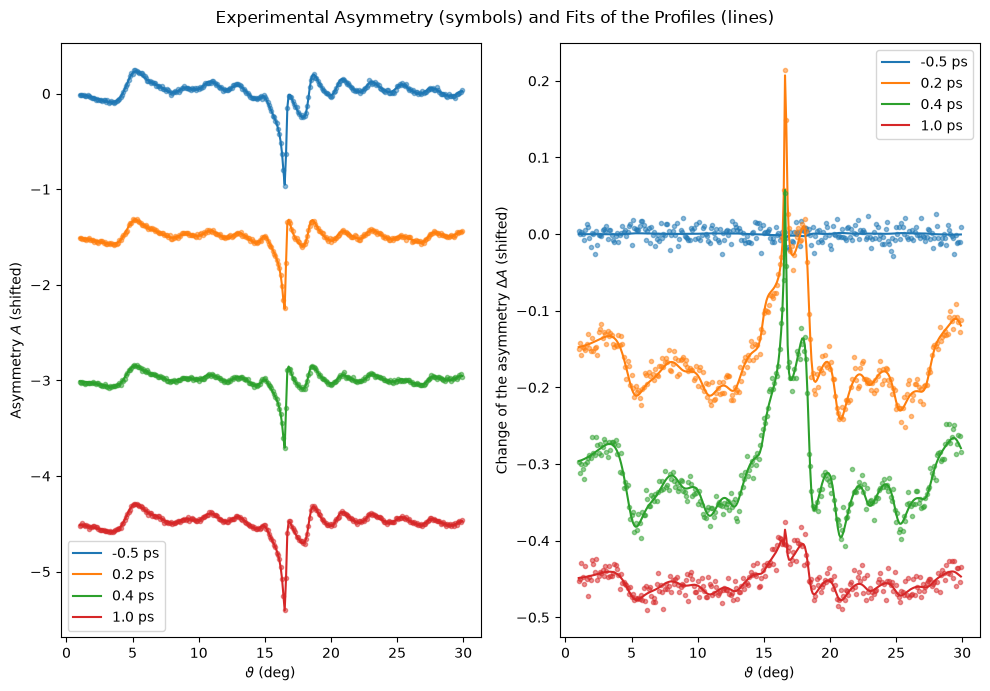

In [19]:
selected = [0, 14, 18, 30]  # delays of -0.5, 0.2, 0.4, and 1.0 ps
profile_change = profile_asym - profile_asym[before].mean(axis=0)

plt.figure(figsize=[10, 7])
for k, i in enumerate(selected):
    plt.subplot(1, 2, 1)
    line = plt.plot(theta, exp_asym[i] - 1.5 * k, "o", ms=3, alpha=0.5)
    color = line[0].get_color()
    plt.plot(theta, profile_asym[i] - 1.5 * k, color=color, label=f"{delays_ps[i]:.1f~P}")
    plt.subplot(1, 2, 2)
    plt.plot(theta, exp_change[i] - 0.15 * k, "o", ms=3, alpha=0.5, color=color)
    plt.plot(theta, profile_change[i] - 0.15 * k, color=color, label=f"{delays_ps[i]:.1f~P}")
for k, label in enumerate(["Asymmetry $A$", r"Change of the asymmetry $\Delta A$"]):
    plt.subplot(1, 2, k + 1)
    plt.xlabel(r"$\vartheta$ (deg)")
    plt.ylabel(f"{label} (shifted)")
    plt.legend()
plt.suptitle("Experimental Asymmetry (symbols) and Fits of the Profiles (lines)")
plt.tight_layout()
plt.show()

The fitted linear profiles are compared with the magnetization profiles of the M3TM, which were used to generate the data, for the same delays, where the bands mark the uncertainties of $m_0$, $m_1$, and $m_2$:

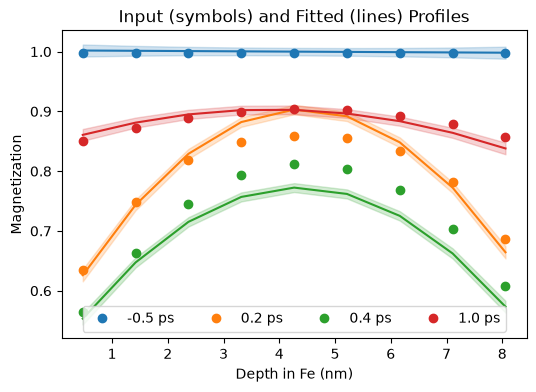

In [20]:
plt.figure(figsize=[6, 4])
for i in selected:
    values, errors = profiles[i].T
    fit_profile = values @ basis
    band = np.sqrt((errors[:, np.newaxis] ** 2 * basis**2).sum(axis=0))
    line = plt.plot(
        depth_Fe, res_mag.magnetization_map[i, Fe_layers, 1], "o", label=f"{delays_ps[i]:.1f~P}"
    )
    plt.plot(depth_Fe, fit_profile, color=line[0].get_color())
    plt.fill_between(
        depth_Fe, fit_profile - band, fit_profile + band, color=line[0].get_color(), alpha=0.2
    )
plt.xlabel("Depth in Fe (nm)")
plt.ylabel("Magnetization")
plt.legend(loc="lower center", ncols=4)
plt.title("Input (symbols) and Fitted (lines) Profiles")
plt.show()

The fit of the profiles recovers the average magnetization of the M3TM and the curvature of the profile, i.e. the stronger demagnetization at the interfaces of the Fe layer.
At early delays, the quadratic profile is too smooth for the steep demagnetization at the interfaces, which is an example of the bias of an assumed profile.
The uncertainties of the shape of the profile are much larger than the one of its average, as the asymmetry is less sensitive to the shape of the profile than to its average.

### Forward Fit of the M3TM

Instead of guessing analytical magnetization profiles for every delay, the `magnetization_map` can also be calculated by a physical model, whose few parameters are fitted to all delays at once.
Here, the demagnetization rate $R$ and the electron-phonon coupling $g$ of Fe are fitted, while all other parameters are kept at the values of the data generation.
They are scaled to the order of one, i.e. $R$ in 1/ps and $g$ in $10^{17}$ W/(m³ K), and start far from their true values.
Each evaluation of the fit runs the M3TM and the resonant magnetic reflectivity for all delays by {py:meth}`calc_temp_map <udkm1Dsim.simulations.heat.Heat.calc_temp_map>` and {py:meth}`calc_inhomogeneous_reflectivity_transmissivity <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.calc_inhomogeneous_reflectivity_transmissivity>`.

In [21]:
def forward_asymmetry(params):
    R_m3tm, g_m3tm = params["R"] * 1e12, params["g"] * 1e17
    for layer in [Fe_top, Fe_bulk]:
        layer.thermal.sub_system_coupling = [
            f"-{g_m3tm}*(T_0-T_1)",
            f"{g_m3tm}*(T_0-T_1)",
            f"{R_m3tm}*T_2*T_1/{Tc}*(1-T_2*(1+2/(exp(2*T_2*{Tc}/T_0)-1)))",
        ]
    temp_map, _, _ = h.calc_temp_map(delays, init_temp)
    magnetization_map = np.zeros([len(delays), L, 3])
    magnetization_map[:, :, 1] = temp_map[:, :, 2]
    R, R_phi, _, _ = elzo.calc_inhomogeneous_reflectivity_transmissivity(
        magnetization_map=magnetization_map
    )
    return ((R - R_phi) / (R + R_phi))[:, 0, :]


forward_params = lmfit.Parameters()
forward_params.add("R", 10, min=1, max=100)  # 1/ps
forward_params.add("g", 3, min=0.5, max=50)  # 1e17 W/m³/K

forward_result = lmfit.minimize(
    lambda params: (forward_asymmetry(params) - exp_asym).flatten(), forward_params
)
forward_result

In [22]:
R_fit, g_fit = forward_result.params["R"], forward_result.params["g"]
print(f"R = {R_fit.value:.2f} ± {R_fit.stderr:.2f} 1/ps, input {R_Fe * 1e-12:g} 1/ps")
print(
    f"g = {g_fit.value:.2f} ± {g_fit.stderr:.2f} 1e17 W/m³/K, input {g_Fe * 1e-17:g} 1e17 W/m³/K"
)

R = 20.12 ± 0.09 1/ps, input 20 1/ps
g = 7.08 ± 0.04 1e17 W/m³/K, input 7 1e17 W/m³/K


The forward fit recovers the demagnetization rate and the electron-phonon coupling of the input within their uncertainties, which are given by the noise of the data.
In contrast to the fit of the profiles, it requires only two parameters for all delays instead of two per delay, and its `magnetization_map` is physically consistent in space and time.
In reality, further parameters, e.g. the fluence, the Curie temperature, or the thermal conductivities, can be fitted the same way, but might be strongly correlated.

## Gallery Plot

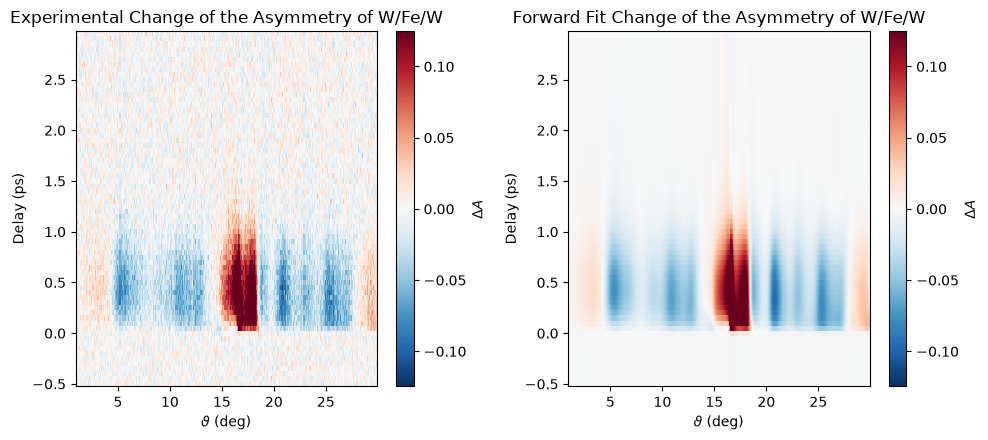

In [23]:
fit_asym = forward_asymmetry(forward_result.params)
fit_change = fit_asym - fit_asym[before].mean(axis=0)

plt.figure(figsize=[10, 4.5])
for k, (change, title) in enumerate([(exp_change, "Experimental"), (fit_change, "Forward Fit")]):
    plt.subplot(1, 2, k + 1)
    plt.pcolormesh(
        theta,
        delays_ps,
        change,
        shading="auto",
        cmap="RdBu_r",
        vmin=-vmax,
        vmax=vmax,
    )
    plt.colorbar(label=r"$\Delta A$")
    plt.xlabel(r"$\vartheta$ (deg)")
    plt.ylabel("Delay (ps)")
    plt.title(f"{title} Change of the Asymmetry of W/Fe/W")
plt.tight_layout()
plt.show()